# 04 &nbsp;Do retrieval scores predict the answers?

Retrieval scores are cheap: they need no answer model and no grading. If they rank configurations the same way answer accuracy does, a team can tune retrieval alone and skip most of the expensive part. This notebook joins the retrieval scores from notebook 02 with the graded answers from notebook 03, for the same questions and the same 24 configurations.

- **Retrieval score:** on MultiHop-RAG, the share of evidence sentences retrieved; on Natural Questions, whether a retrieved chunk from the gold page contains a gold answer.
- **Accuracy:** the share of answerable questions answered correctly.

In [1]:
import warnings

warnings.filterwarnings("ignore", message="urllib3 v2 only supports OpenSSL")  # old SSL on macOS system Python

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from ragdecisions import style
from ragdecisions.data import DATASETS, RESULTS_DIR, load_questions
from ragdecisions.stats import bootstrap_means, interval, resample_indices

style.use_style()
KEYS = ["chunk", "retriever", "rerank", "k"]
SCORE = {"multihop_rag": "evidence_recall", "natural_questions": "answer_hit"}

retrieval = pd.read_csv(RESULTS_DIR / "retrieval.csv", keep_default_na=False, na_values=[""])
retrieval["rerank"] = retrieval["rerank"].astype(str).eq("True")
for column in ["answer_hit", "all_evidence"]:
    retrieval[column] = retrieval[column].map({"True": 1.0, "False": 0.0, True: 1.0, False: 0.0})


def joined(dataset):
    answers = pd.read_csv(RESULTS_DIR / f"answers_{dataset}.csv", keep_default_na=False, na_values=[""])
    grades = pd.read_csv(RESULTS_DIR / f"grades_{dataset}.csv", keep_default_na=False, na_values=[""])
    t = answers.merge(grades[["qid", "answer", "correct"]], on=["qid", "answer"])
    t["correct"] = t["correct"].astype(str).eq("True").astype(float)
    t["rerank"] = t["rerank"].astype(str).eq("True")
    types = load_questions(dataset).set_index("qid")["type"]
    t = t[t["qid"].map(types) != "null"]
    knew = t[t["k"] == 0].set_index("qid")["correct"].eq(1)
    t = t[t["k"] > 0].merge(retrieval[retrieval["dataset"] == dataset][["qid", *KEYS, "evidence_recall", "all_evidence", "answer_hit"]],
                            on=["qid", *KEYS])
    t["score"] = t[SCORE[dataset]]
    t["knew"] = t["qid"].map(knew)
    return t


data = {name: joined(name) for name in DATASETS}
for name, t in data.items():
    print(f"{DATASETS[name]}: {t['qid'].nunique()} answerable questions x {t.groupby(KEYS).ngroups} configurations")

MultiHop-RAG: 133 answerable questions x 24 configurations
Natural Questions: 100 answerable questions x 24 configurations


## 1. Across configurations: does a better retrieval score mean better answers?

Each point is one of the 24 configurations. The rank correlation says how well ordering configurations by retrieval score matches ordering them by accuracy (1 is a perfect match). Its interval comes from resampling questions.

In [2]:
def rank_correlation(t, n_boot=2000):
    score = t.pivot_table(index="qid", columns=KEYS, values="score")
    correct = t.pivot_table(index="qid", columns=KEYS, values="correct")[score.columns]
    observed = spearmanr(score.mean(), correct.mean()).correlation
    draws = [spearmanr(score.values[i].mean(axis=0), correct.values[i].mean(axis=0)).correlation
             for i in resample_indices(len(score), n_boot=n_boot)]
    low, high = interval(np.array(draws))
    return observed, low, high


correlations = pd.DataFrame({DATASETS[name]: dict(zip(["rank correlation", "low", "high"], rank_correlation(t)))
                             for name, t in data.items()}).T
correlations.style.format("{:.2f}")

,rank correlation,low,high
MultiHop-RAG,0.96,0.88,0.97
Natural Questions,0.95,0.80,0.97


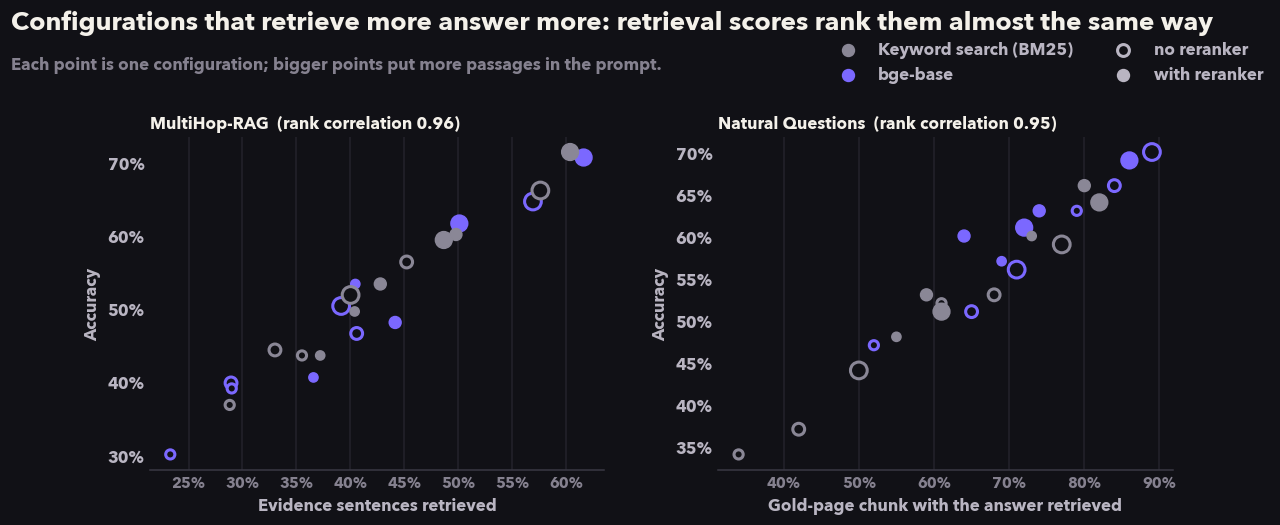

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, name in zip(axes, DATASETS):
    cfg = data[name].groupby(KEYS).agg(score=("score", "mean"), accuracy=("correct", "mean")).reset_index()
    for (key, reranked), part in cfg.groupby(["retriever", "rerank"]):
        color = style.RETRIEVER_COLORS[key]
        kwargs = {"color": color} if reranked else {"facecolor": style.SURFACE, "edgecolor": color, "lw": 2}
        ax.scatter(part["score"], part["accuracy"], s=part["k"] * 12, zorder=3, **kwargs)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("Evidence sentences retrieved" if name == "multihop_rag" else "Gold-page chunk with the answer retrieved")
    ax.set_ylabel("Accuracy")
    rho = correlations.loc[DATASETS[name], "rank correlation"]
    ax.set_title(f"{DATASETS[name]}  (rank correlation {rho:.2f})", loc="left", color=style.INK, fontsize=11)
for key in ["bm25", "bge-base"]:
    axes[0].scatter([], [], s=60, color=style.RETRIEVER_COLORS[key], label=style.RETRIEVER_LABELS[key])
axes[0].scatter([], [], s=60, facecolor=style.SURFACE, edgecolor=style.INK_2, lw=2, label="no reranker")
axes[0].scatter([], [], s=60, color=style.INK_2, label="with reranker")
fig.legend(loc="upper right", bbox_to_anchor=(0.98, 0.95), ncol=2)
style.headline(fig, "Configurations that retrieve more answer more: retrieval scores rank them almost the same way",
               "Each point is one configuration; bigger points put more passages in the prompt.")
fig.subplots_adjust(top=0.74, wspace=0.25)
style.save(fig, "retrieval_vs_accuracy")
plt.show()

## 2. Question by question: does finding the evidence mean a right answer?

Split by whether the model answered the question correctly with no documents, since a model that already knows the answer needs retrieval less.

In [4]:
mhr = data["multihop_rag"]
mhr["evidence found"] = pd.cut(mhr["evidence_recall"], [-0.01, 0, 0.99, 1], labels=["none", "some", "all"])
by_evidence = mhr.pivot_table(index="evidence found", columns="knew", values="correct", aggfunc="mean", observed=True)
by_evidence.columns = ["didn't know it without documents", "knew it without documents"]
print("MultiHop-RAG, accuracy by how much evidence was retrieved")
display(by_evidence.style.format("{:.0%}"))

nq = data["natural_questions"]
by_hit = nq.pivot_table(index="answer_hit", columns="knew", values="correct", aggfunc="mean")
by_hit.index = ["answer not retrieved", "answer retrieved"]
by_hit.columns = ["didn't know it without documents", "knew it without documents"]
print("Natural Questions, accuracy by whether a gold-page chunk with the answer was retrieved")
display(by_hit.style.format("{:.0%}"))

from ragdecisions.grading import is_decline

for name, t, missed in [("multihop_rag", mhr, mhr["evidence_recall"] == 0), ("natural_questions", nq, nq["answer_hit"] == 0)]:
    cell = t[t["knew"] & missed]
    declined = cell["answer"].map(is_decline)
    print(f"{DATASETS[name]}, questions it knew but retrieval missed: {cell['correct'].mean():.0%} right, "
          f"{declined.mean():.0%} declined, {((cell['correct'] == 0) & ~declined).mean():.0%} wrong answers")

MultiHop-RAG, accuracy by how much evidence was retrieved


,didn't know it without documents,knew it without documents
evidence found,,
none,17%,35%
some,46%,72%
all,71%,97%


Natural Questions, accuracy by whether a gold-page chunk with the answer was retrieved


,didn't know it without documents,knew it without documents
answer not retrieved,14%,50%
answer retrieved,69%,88%


MultiHop-RAG, questions it knew but retrieval missed: 35% right, 63% declined, 2% wrong answers
Natural Questions, questions it knew but retrieval missed: 50% right, 32% declined, 18% wrong answers


Finding the evidence matters a great deal, but it is not enough. On MultiHop-RAG, for questions the model could not answer without documents, accuracy rises from 17% when none of the evidence was retrieved to 46% when some was and 71% when all of it was. On Natural Questions it rises from 14% to 69% when the answer was retrieved, so even with the answer in the prompt the model misses about three in ten.

A retrieval miss can also cost what the model already knows. Questions it answered correctly with no documents are answered correctly only 35% of the time on MultiHop-RAG, and 50% on Natural Questions, when retrieval misses. On MultiHop-RAG it mostly declines, as the prompt tells it to answer only from the passages; on Natural Questions it declines a third of the time and gives a wrong answer about a fifth of the time.

## 3. Do retrieval effects predict answer effects?

The same comparison as in notebooks 02 and 03, on the same questions and the same 24 configurations: how much each choice changes the retrieval score, and how much it changes accuracy.

In [5]:
CONTRASTS = [
    ("Add the reranker", "rerank", True, False),
    ("bge-base instead of keyword search", "retriever", "bge-base", "bm25"),
    ("512-token chunks instead of 128", "chunk", 512, 128),
    ("10 passages instead of 3", "k", 10, 3),
]


def effect(t, measure, column, a, b):
    if column == "k":
        t = t[t["k"].isin([a, b])]
    per_question = t.groupby(["qid", column])[measure].mean().unstack(column)
    return (per_question[a] - per_question[b]).mean() * 100


side_by_side = pd.concat({
    DATASETS[name]: pd.DataFrame({label: {"retrieval": effect(t, "score", col, a, b), "accuracy": effect(t, "correct", col, a, b)}
                                  for label, col, a, b in CONTRASTS}).T
    for name, t in data.items()
}, axis=1)
side_by_side.style.format("{:+.1f}")

On MultiHop-RAG, retrieval effects predict accuracy effects closely: every choice moves accuracy within about 2 points of how it moves retrieval. On Natural Questions every choice moves both in the same direction, but the retrieval score overstates the gain from longer chunks and more passages: 512-token chunks add 19.8 points of retrieval and 12.2 of accuracy, and ten passages add 13.2 and 7.5.

This also settles the reranker question from notebook 03. On the same 100 questions and 24 configurations, the reranker adds 5.2 points of retrieval and 6.1 of accuracy. The 2.1 points in notebook 02 averaged over all 200 questions and all 54 configurations, including MiniLM and 256-token chunks.

## What this tells us

- **Retrieval scores rank configurations almost exactly as answers do.** The rank correlation between retrieval score and accuracy across the 24 configurations is 0.96 on MultiHop-RAG and 0.95 on Natural Questions, with intervals starting at 0.88 and 0.80. To choose among configurations like these, tuning retrieval alone gets nearly the same order, without generating or grading a single answer.
- **They do not say how much a change is worth.** On Natural Questions, about 60% of the retrieval gain from longer chunks or more passages shows up as accuracy. Pricing a change needs answers, at least for the final few candidates.
- **Retrieval is necessary, not sufficient.** Even with the answer retrieved, the model misses about three in ten questions it could not answer alone.
- **A retrieval miss can undo what the model knows,** mostly because it declines when the passages do not contain the answer.

Next: [notebook 05](05_cost.ipynb) puts a price on each configuration and finds the cheapest one that meets a quality bar.